In [8]:
#!/usr/bin/env python3
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

U = 8.0
steps_max = 1000
broaden = eta = 0.2
omega_max = 8.0
scale_intensity = 1.0
omega = np.linspace(-omega_max, omega_max, 300 + 1)

L = 6
Nup = L // 2
Ndn = L // 2
target_q = 0
f_values = np.arange(0, 41, 1)
phi_over_phi0 = f_values / 40.0
base_dir = Path('./data')


In [9]:
def parse_green_file(filename):
    filename = Path(filename)
    print(f"Name of file to be processed: {filename}")
    contents = filename.read_text().splitlines()

    data = {
        "L": None,
        "U": None,
        "E0": None,
        "Gap": None,
        "Q": [],
        "nrm2": [],
        "a": [],
        "b": [],
    }

    for line in contents:
        line_data = line.split()
        if not line_data:
            continue
        key = line_data[0]
        if key == 'L':
            data['L'] = int(line_data[1])
        elif key == 'U':
            data['U'] = float(line_data[1])
        elif key == 'E0':
            data['E0'] = float(line_data[1])
        elif key == 'Gap':
            data['Gap'] = float(line_data[1])
        elif key == 'Q':
            data['Q'].append(int(line_data[1]))
        elif key == 'nrm2':
            data['nrm2'].append(float(line_data[1]))
        elif key == 'a':
            data['a'].append(np.array([float(x) for x in line_data[1:]], dtype=float))
        elif key == 'b':
            data['b'].append(np.array([float(x) for x in line_data[1:]], dtype=float))
    return data


In [10]:
def cfractionh(a, b, length):
    res = 0.0
    for j in range(length - 1, 0, -1):
        res = -b[j] * b[j] / (a[j] + res)
    return a[0] + res


def cfractionp(a, b, length):
    res = 0.0
    for j in range(length - 1, 0, -1):
        res = -b[j] * b[j] / (a[j] + res)
    return a[0] + res


def sqwh(w, eta, a, b, length, nrm2, E0):
    a2 = []
    for j in range(length):
        a2.append(w + U / 2 - E0 + complex(0, eta) + a[j])
    denominator = cfractionh(a2, b, length)
    return -2.0 * (nrm2 * nrm2 / denominator).imag


def RGqh(w, eta, a, b, length, nrm2, E0):
    a2 = []
    for j in range(length):
        a2.append(w + U / 2 - E0 + complex(0, eta) + a[j])
    denominator = cfractionh(a2, b, length)
    return -2.0 * (nrm2 * nrm2 / denominator).real


def sqwp(w, eta, a, b, length, nrm2, E0):
    a2 = []
    for j in range(length):
        a2.append(w + U / 2 + E0 + complex(0, eta) - a[j])
    denominator = cfractionp(a2, b, length)
    return -2.0 * (nrm2 * nrm2 / denominator).imag


def RGqp(w, eta, a, b, length, nrm2, E0):
    a2 = []
    for j in range(length):
        a2.append(w + U / 2 + E0 + complex(0, eta) - a[j])
    denominator = cfractionp(a2, b, length)
    return -2.0 * (nrm2 * nrm2 / denominator).real


def extract_q_component(data, q_target, imag_fn, real_fn):
    imag_part = np.zeros(len(omega), dtype=float)
    real_part = np.zeros(len(omega), dtype=float)

    for q_idx, momentum in enumerate(data['Q']):
        if momentum != q_target:
            continue
        if data['nrm2'][q_idx] <= 1.0e-9:
            return imag_part, real_part

        steps = min(steps_max, data['a'][q_idx].shape[0])
        for w_idx, w in enumerate(omega):
            imag_part[w_idx] = imag_fn(w, broaden, data['a'][q_idx], data['b'][q_idx], steps, data['nrm2'][q_idx], data['E0'])
            real_part[w_idx] = real_fn(w, broaden, data['a'][q_idx], data['b'][q_idx], steps, data['nrm2'][q_idx], data['E0'])
        return imag_part, real_part

    raise ValueError(f"Q={q_target} not found in {data['Q']}")


In [11]:
Gall = np.zeros((len(f_values), len(omega)), dtype=float)
rGall = np.zeros((len(f_values), len(omega)), dtype=float)

for i, f in enumerate(f_values):
    gh_file = base_dir / f'L{L}Nup{Nup}Ndn{Ndn}f{f}Q0_Gh.dat'
    gp_file = base_dir / f'L{L}Nup{Nup}Ndn{Ndn}f{f}Q0_Gp.dat'

    gh_data = parse_green_file(gh_file)
    gp_data = parse_green_file(gp_file)

    Gh, rGh = extract_q_component(gh_data, target_q, sqwh, RGqh)
    Gp, rGp = extract_q_component(gp_data, target_q, sqwp, RGqp)

    Gall[i, :] = Gh + Gp
    rGall[i, :] = rGh + rGp


Name of file to be processed: data/L6Nup3Ndn3f0Q0_Gh.dat
Name of file to be processed: data/L6Nup3Ndn3f0Q0_Gp.dat
Name of file to be processed: data/L6Nup3Ndn3f1Q0_Gh.dat
Name of file to be processed: data/L6Nup3Ndn3f1Q0_Gp.dat
Name of file to be processed: data/L6Nup3Ndn3f2Q0_Gh.dat
Name of file to be processed: data/L6Nup3Ndn3f2Q0_Gp.dat
Name of file to be processed: data/L6Nup3Ndn3f3Q0_Gh.dat
Name of file to be processed: data/L6Nup3Ndn3f3Q0_Gp.dat
Name of file to be processed: data/L6Nup3Ndn3f4Q0_Gh.dat
Name of file to be processed: data/L6Nup3Ndn3f4Q0_Gp.dat
Name of file to be processed: data/L6Nup3Ndn3f5Q0_Gh.dat
Name of file to be processed: data/L6Nup3Ndn3f5Q0_Gp.dat
Name of file to be processed: data/L6Nup3Ndn3f6Q0_Gh.dat
Name of file to be processed: data/L6Nup3Ndn3f6Q0_Gp.dat
Name of file to be processed: data/L6Nup3Ndn3f7Q0_Gh.dat
Name of file to be processed: data/L6Nup3Ndn3f7Q0_Gp.dat
Name of file to be processed: data/L6Nup3Ndn3f8Q0_Gh.dat
Name of file to be processed: d

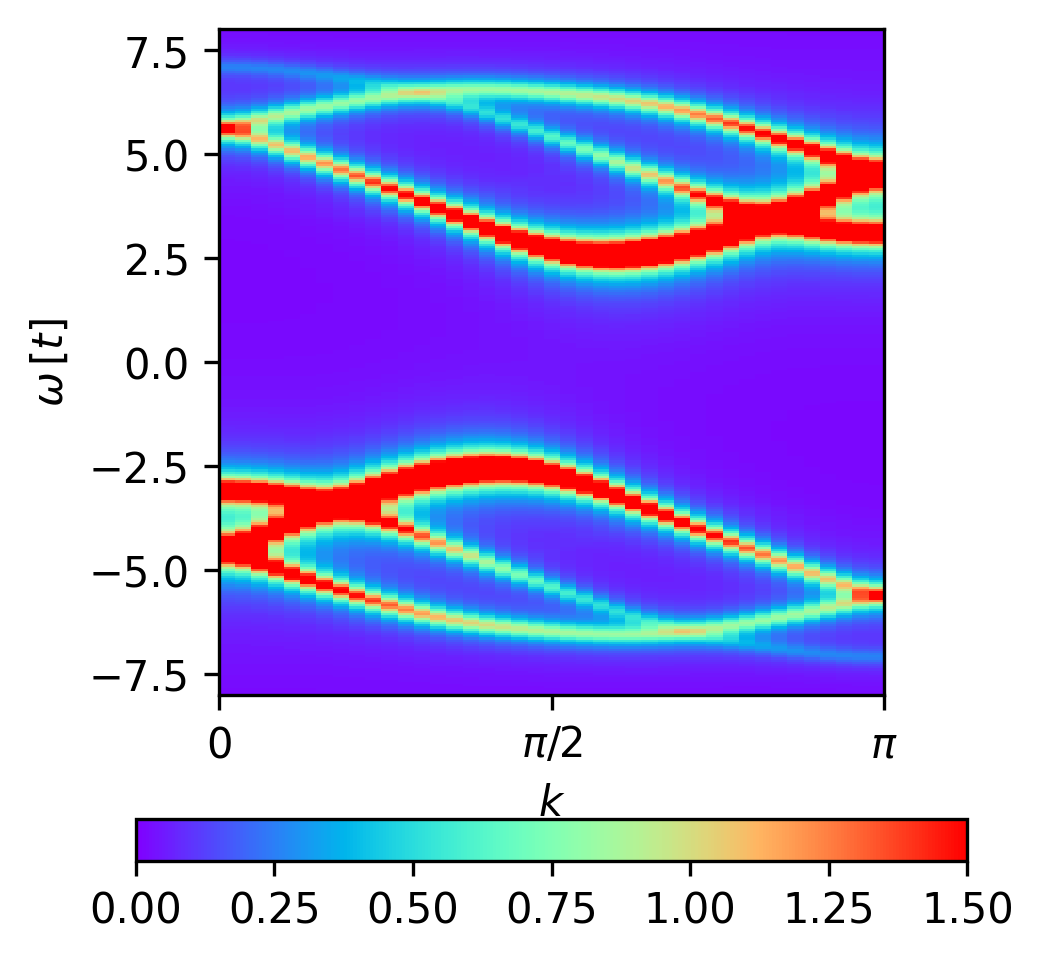

In [12]:
fig, ax = plt.subplots(figsize=(4.8, 3.6), dpi=300)
fsize = 10
plt.rcParams.update({'font.size': fsize})

extent = (phi_over_phi0[0], phi_over_phi0[-1], omega[0], omega[-1])
aspect = (extent[1] - extent[0]) / (extent[3] - extent[2])

im = ax.imshow(
    Gall.T,
    origin='lower',
    extent=extent,
    aspect=aspect,
    interpolation='none',
    vmax=1.5,
    vmin=0.0,
    cmap='rainbow'
)
ax.set_xlabel(r'$k$')
ax.set_ylabel(r'$\omega\,[t]$')
ax.set_xticks([0.0, 0.5, 1.0])
ax.set_xticklabels([r'$0$', r'$\pi/2$', r'$\pi$'])
fig.colorbar(im, ax=ax, orientation='horizontal', fraction=0.05, pad=0.15)
fig.savefig(f'../plot_G1d_hf_imag_{Path.cwd().name}.png', bbox_inches='tight', dpi=300)
plt.show()



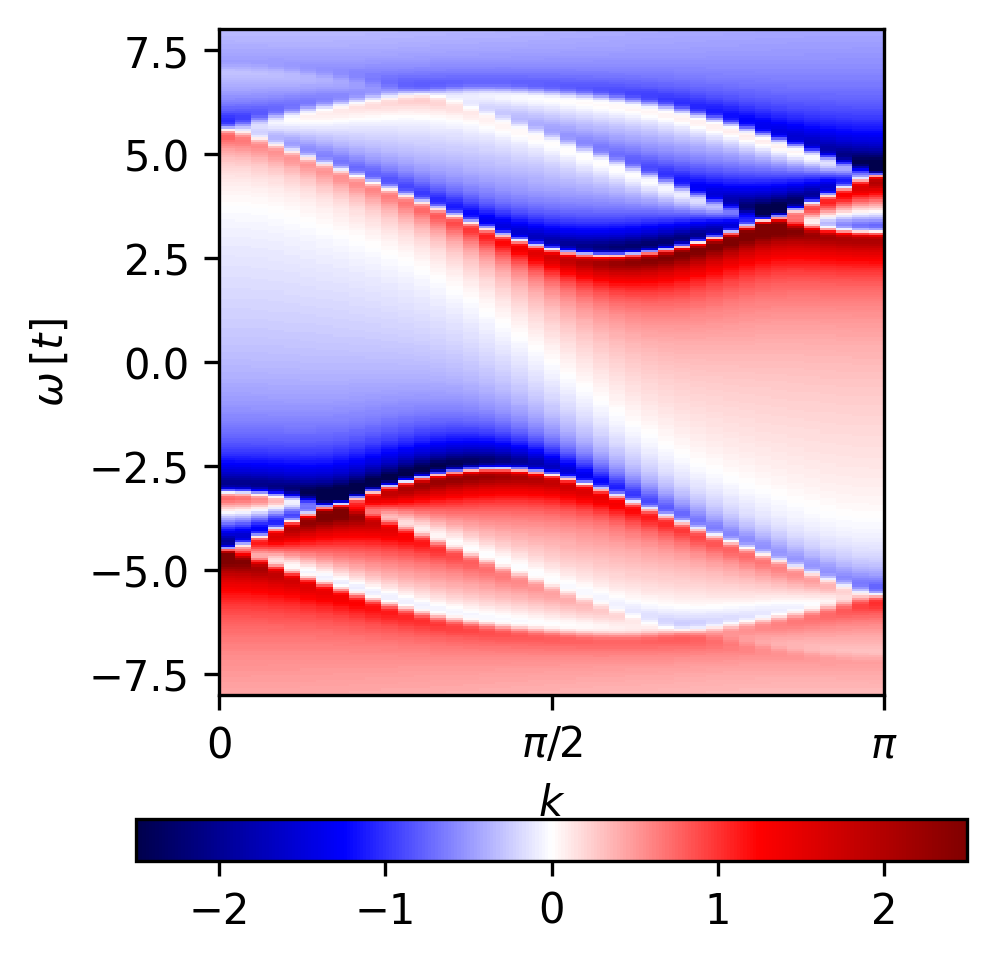

In [13]:
fig, ax = plt.subplots(figsize=(4.8, 3.6), dpi=300)
fsize = 10
plt.rcParams.update({'font.size': fsize})

extent = (phi_over_phi0[0], phi_over_phi0[-1], omega[0], omega[-1])
aspect = (extent[1] - extent[0]) / (extent[3] - extent[2])

im = ax.imshow(
    rGall.T,
    origin='lower',
    extent=extent,
    aspect=aspect,
    interpolation='none',
    vmax=2.5,
    vmin=-2.5,
    cmap='seismic'
)
ax.set_xlabel(r'$k$')
ax.set_ylabel(r'$\omega\,[t]$')
ax.set_xticks([0.0, 0.5, 1.0])
ax.set_xticklabels([r'$0$', r'$\pi/2$', r'$\pi$'])
fig.colorbar(im, ax=ax, orientation='horizontal', fraction=0.05, pad=0.15)
fig.savefig(f'../plot_G1d_hf_real_{Path.cwd().name}.png', bbox_inches='tight', dpi=300)
plt.show()

